Excercise 7.1

This exercise is solved using code from the [Git Hub pySINDy](https://github.com/dynamicslab/pysindy/blob/master/examples/15_pysindy_lectures.ipynb)

Import necesarry modules

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import pandas as pd

# SINDy imports
import pysindy as ps
from pysindy.utils import lorenz

Initialize seed and integrator details from pySINDY

In [2]:
# Initialize integrator keywords for solve_ivp to replicate the odeint defaults
integrator_keywords = {}
integrator_keywords['rtol'] = 1e-12
integrator_keywords['method'] = 'LSODA'
integrator_keywords['atol'] = 1e-12

Generate data for the Lorenz system using the lorenz pySINDy import

In [3]:
# define the testing and training Lorenz data we will use for these examples
dt_base = 0.0001 # time step from exercise 7.4
t_train = np.arange(0, 100, dt_base) # time vector for training data

x0_train = [-8, 8, 27] # Initial values from pySINDy GitHub

t_train_span = (t_train[0], t_train[-1])
x_train = solve_ivp(
    lorenz, t_train_span, x0_train, t_eval=t_train, **integrator_keywords
).y.T

Now SINDy is used to generate models which fit to this data.

In [5]:
# Fitting SINDy model for different lengths of the training data.
# Code is obtained from the SINDy documentation.
feature_names = ['x', 'y', 'z']
sparse_regression_optimizer = ps.STLSQ(threshold=0.1)  # default is lambda = 0.1
coefs = []
T = [1.2, 1.3, 1.4, 1.5, 1.6, 1.7] # different lengths of training data,
discard_time = 1.0
start_idx = int(round(discard_time / dt_base)) # Discard initial samples until t=1 second
for stop_time in T:
    stop_time -= discard_time
    n_samples = int(round(stop_time / dt_base))
    training_data = x_train[start_idx:start_idx+n_samples] # Train from t = 1 to t = 1 + stop*dt
    model = ps.SINDy(optimizer=sparse_regression_optimizer)
    model.fit(training_data, t=dt_base, feature_names=feature_names)
    print(f"Model trained with {n_samples} samples after t={discard_time:g}:")
    model.print()
    coefs.append(model.coefficients())


Model trained with 2000 samples after t=1:
(x)' = -10.000 x +  10.000 y
(y)' =  0.056 1 +  5.412 x +  10.307 y + -1.919 z + -1.434 x^2 +  0.160 x y + -0.184 x z +  0.209 y^2 + -0.153 y z +  0.096 z^2
(z)' = -2.667 z +  1.000 x y
Model trained with 3000 samples after t=1:
(x)' = -10.000 x +  10.000 y
(y)' =  0.544 1 +  3.222 x +  9.842 y +  0.359 z + -1.399 x^2 +  0.433 x y +  0.115 y^2 + -0.276 y z
(z)' = -2.667 z +  1.000 x y
Model trained with 4000 samples after t=1:
(x)' = -10.000 x +  10.000 y
(y)' =  28.000 x + -1.000 y + -1.000 x z
(z)' = -2.667 z +  1.000 x y
Model trained with 5000 samples after t=1:
(x)' = -10.000 x +  10.000 y
(y)' = -0.001 1 +  28.000 x + -1.000 y + -1.000 x z
(z)' = -2.667 z +  1.000 x y
Model trained with 6000 samples after t=1:
(x)' = -10.000 x +  10.000 y
(y)' =  28.000 x + -1.000 y + -1.000 x z
(z)' = -2.667 z +  1.000 x y
Model trained with 7000 samples after t=1:
(x)' = -10.000 x +  10.000 y
(y)' =  28.000 x + -1.000 y + -1.000 x z
(z)' = -2.667 z +  

It is seen from the model output that training on 4000 samples after t = 1, corresponding to T = 1.4, seems sufficient with the current small step size.

The first 4000 samples after t = 1 of the lorenz model is now plotted.

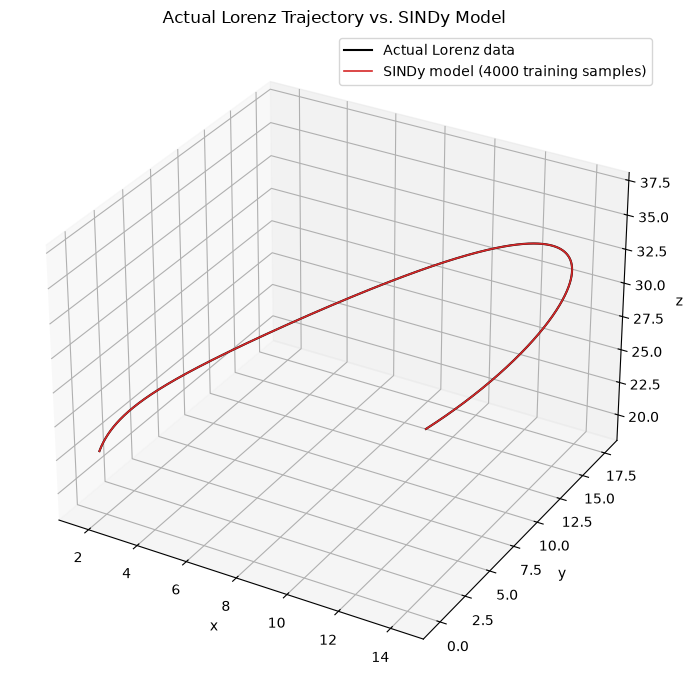

In [6]:
# This plotting code was generated using the 3D Lorenz plotting from the pySINDy documentation, together with GPT-6 Luna
# Compare the actual data with the SINDy model trained on 4000 samples
n_train_samples = 4000

sparse_regression_optimizer.coef_ = coefs[2]
actual_trajectory = x_train[start_idx:start_idx+n_train_samples]
t_plot = t_train[start_idx:start_idx+n_train_samples]
predicted_trajectory = model.simulate(actual_trajectory[0], t_plot, integrator="odeint")

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot(
    actual_trajectory[:, 0],
    actual_trajectory[:, 1],
    actual_trajectory[:, 2],
    color="black",
    linewidth=1.5,
    label="Actual Lorenz data",
)
ax.plot(
    predicted_trajectory[:, 0],
    predicted_trajectory[:, 1],
    predicted_trajectory[:, 2],
    color="tab:red",
    linewidth=1.2,
    label="SINDy model (4000 training samples)",
)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Actual Lorenz Trajectory vs. SINDy Model")
ax.legend()
plt.tight_layout()
plt.show()

Here it is seen that the SINDy model follows the trajectory perfectly. It is seen that the training time roughly corresponds to one "loop", which the model will roughly follow indefinently as T increases.

b) The simulation is repeated for increasing sampling steps from 0.0001 to 0.1. It is evaluated how the necessary time length changes with increasing sampling steps.

The true model is assumed found, when the discovered model has the correct set of nonzero coefficients, or sparsity pattern, matching the known physics (from Champion article).

In [7]:
# create new optimizer and model
sparse_regression_optimizer_b = ps.STLSQ(threshold=0.1)  # default is lambda = 0.1

# Save "correct" model coefficients and sparsity pattern for comparison
known_coefficients = coefs[2]
known_sparsity = np.abs(known_coefficients) > 0

# Fitting SINDy model for different sampling steps.
dt_list = np.linspace(1e-4, 0.1, 8)
run_results = []

for dt in dt_list:
    start_idx = int(round(discard_time / dt)) # Discard initial samples until t=1 second
    stop_time = 1.5
    stride = int(round(dt /dt_base))  # Adjust stride based on the sampling rate used for solving lorenz
    x_dt = x_train[::stride]
    max_samples = len(x_dt) - start_idx
    while True:
        n_samples = min(int(round((stop_time-discard_time) / dt)), max_samples)
        training_data = x_dt[start_idx:start_idx+n_samples] # Train from t = 1 to t = 1 + stop*dt

        model_b = ps.SINDy(optimizer=sparse_regression_optimizer_b)
        try: # If there are too few data points, prolong the the stop_time
            model_b.fit(
                training_data,
                t=dt,
                feature_names=feature_names
            )
        except ValueError:
            stop_time += 0.5
            continue

        discovered_coefficients = model_b.coefficients()
        discovered_sparsity = np.abs(discovered_coefficients) > 0

        if np.array_equal(discovered_sparsity, known_sparsity): # If both models are non-zero in the same locations, we consider the true model found
            run_results.append({"dt": dt, "status": "Correct model found",
                                "final model": "; ".join(model_b.equations()),
                                "T/dt": (stop_time - discard_time)/dt})
            break
        elif n_samples >= max_samples: # Avoid infinite loop
            run_results.append({"dt": dt, "status": "Max iterations reached",
                                "final model": "; ".join(model_b.equations()),
                                "T/dt": (stop_time - discard_time)/dt})
            break
        else:
            stop_time += 0.5

results_table = pd.DataFrame(run_results)
display(results_table)

,dt,status,final model,T/dt
0,0.000100,Correct model found,-10.000 x + 10.000 y; 28.000 x + -1.000 y + ...,10000.000000
1,0.014371,Correct model found,-9.975 x + 9.974 y; 27.634 x + -0.920 y + -0...,139.165010
2,0.028643,Correct model found,-9.799 x + 9.800 y; 26.223 x + -0.654 y + -0...,261.845387
3,0.042914,Max iterations reached,-9.596 x + 9.597 y; 24.506 x + -0.324 y + -0...,2318.575233
4,0.057186,Max iterations reached,-9.305 x + 9.305 y; 22.070 x + 0.141 y + -0...,1739.945041
5,0.071457,Max iterations reached,-14.448 x + 12.915 y + 0.163 x z + -0.125 y ...,1385.445822
6,0.085729,Max iterations reached,-15.755 x + 13.733 y + 0.214 x z + -0.164 y ...,1154.807532
7,0.100000,Max iterations reached,0.124 1 + -17.191 x + 14.647 y + 0.270 x z ...,990.000000


The number of samples decreases, however at a certain point the model becomes to coarse to be able to solve the system.

c) Now the system is solved where gaussian noise is added.

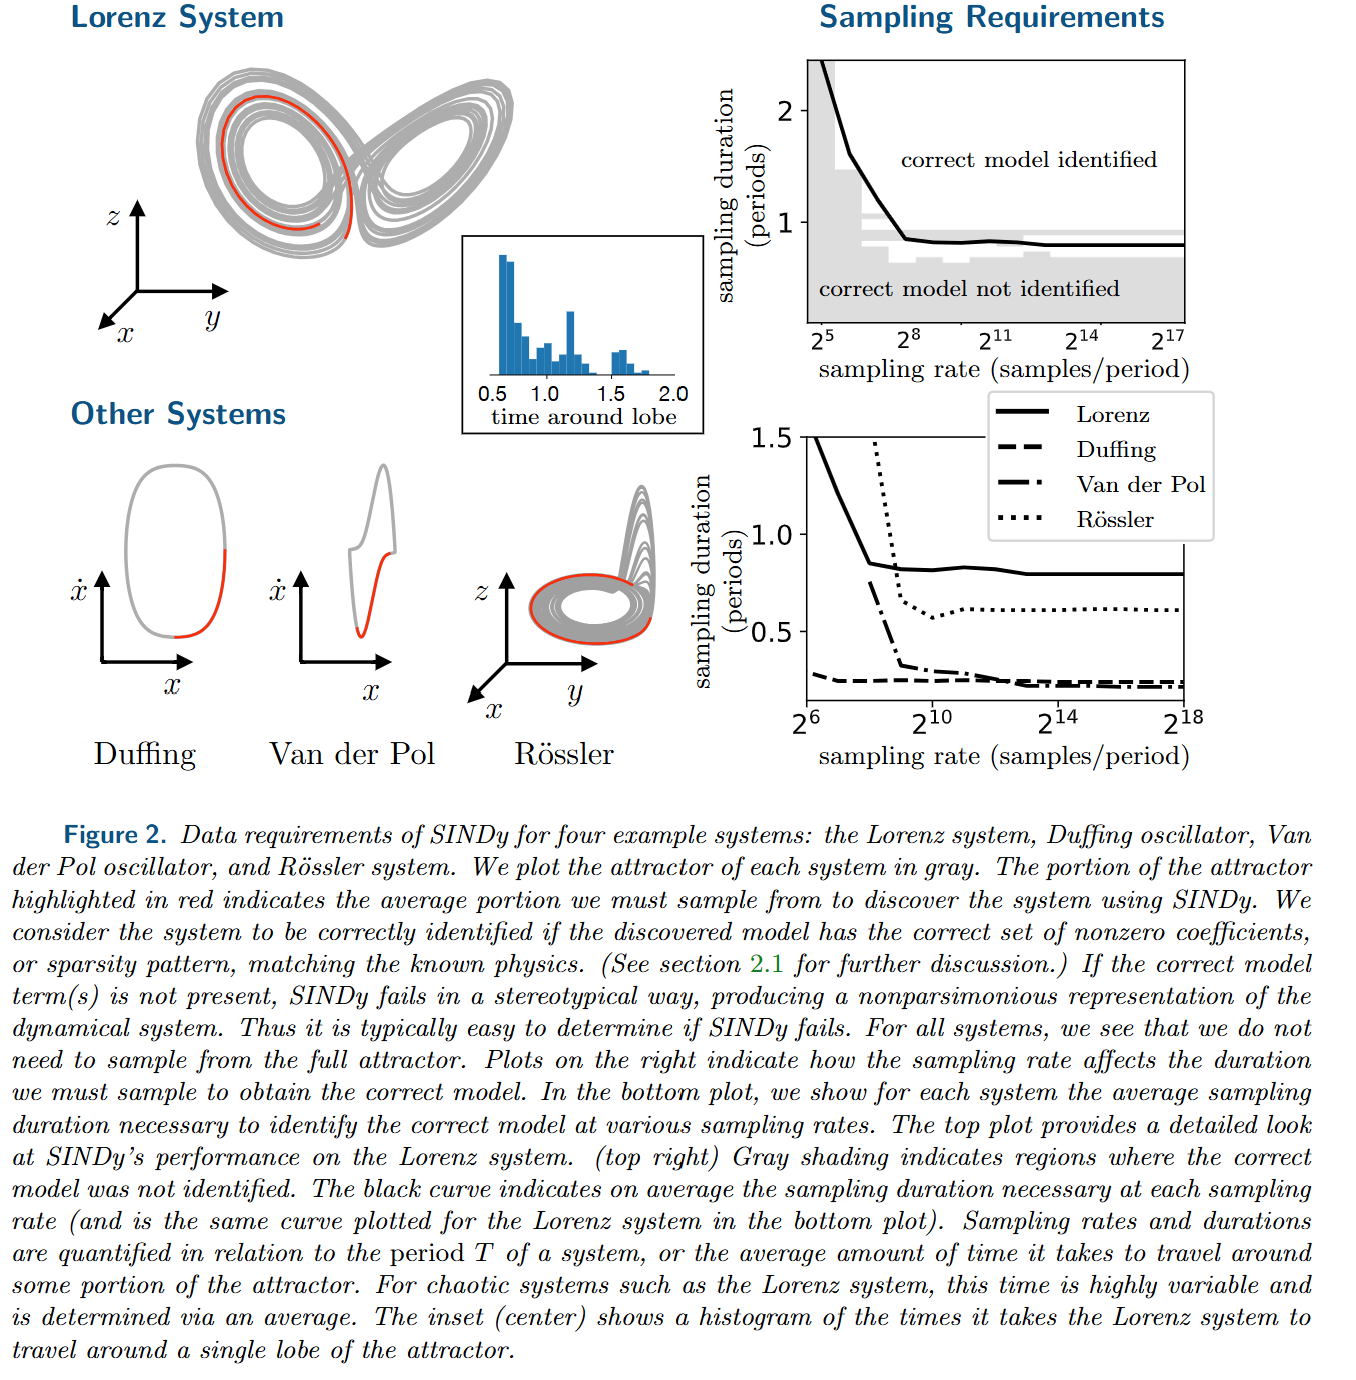

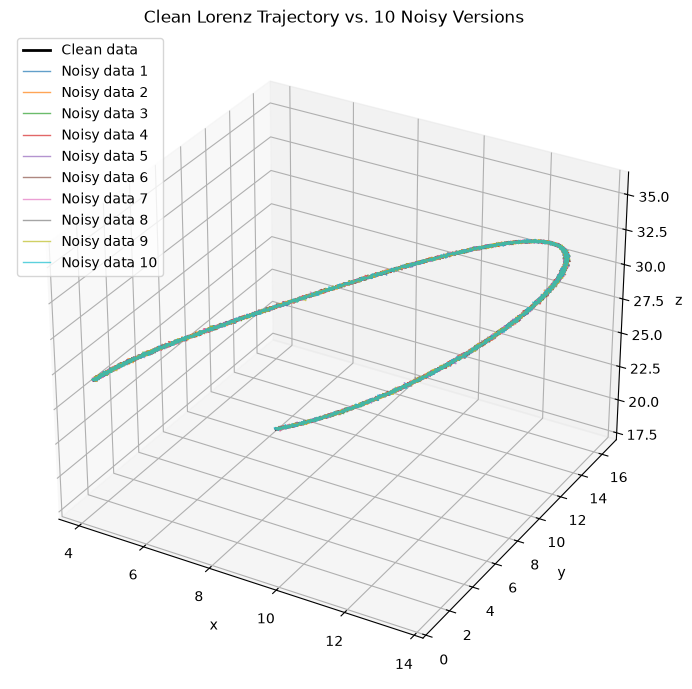

In [22]:
# Add gaussian noise to the training data
# Code is found in the tutorials of the pySINDy documentation
rmse = np.sqrt(np.mean(x_train**2))
x_train_added_noise_list = []
for __ in range(10):
    x_train_added_noise = x_train + np.random.normal(0, rmse / 500.0,  x_train.shape)
    x_train_added_noise_list.append(x_train_added_noise)

# Compare the clean Lorenz trajectory with all 10 noisy versions
n_plot_samples = 4000
actual_trajectory = x_train[start_idx:start_idx + n_plot_samples]

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    actual_trajectory[:, 0],
    actual_trajectory[:, 1],
    actual_trajectory[:, 2],
    color="black",
    linewidth=2,
    label="Clean data",
)

colors = plt.colormaps["tab10"].colors
for i, noisy_data in enumerate(x_train_added_noise_list):
    noisy_trajectory = noisy_data[start_idx:start_idx + n_plot_samples]
    ax.plot(
        noisy_trajectory[:, 0],
        noisy_trajectory[:, 1],
        noisy_trajectory[:, 2],
        color=colors[i],
        alpha=0.7,
        linewidth=1,
        label=f"Noisy data {i + 1}",
    )

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Clean Lorenz Trajectory vs. 10 Noisy Versions")
ax.legend()
plt.tight_layout()
plt.show()



From the Champion paper, the period is defined as: $$T \approx  0.95$$

In [23]:
T_period = 0.95 # from Champion paper

# create new optimizer and model
sparse_regression_optimizer_b = ps.STLSQ(threshold=0.1)  # default is lambda = 0.1

# Fitting SINDy model for different sampling steps.
samples_per_period_list = 2**np.arange(5, 12)  # from Champion paper

dt_list = T_period / samples_per_period_list

run_results = []

for x in x_train_added_noise_list:
    for dt in dt_list:
        start_idx = int(round(discard_time / dt)) # Discard initial samples until t=1 second
        stop_time = 1.4
        stride = int(round(dt / dt_base))  # Adjust stride based on the sampling rate used for solving lorenz
        x_dt = x[::stride]
        max_samples = len(x_dt) - start_idx
        while True:
            n_samples = min(int(round((stop_time-discard_time) / dt)), max_samples)
            training_data = x_dt[start_idx:start_idx+n_samples] # Train from t = 1 to t = 1 + stop*dt


            model_b = ps.SINDy(differentiation_method=ps.SmoothedFiniteDifference(),
                               optimizer=ps.STLSQ(threshold=0.1)) # use smooth d finite difference for noisy data (from pySINDy documentation)
            
            try: # If there are too few data points, prolong the the stop_time
                model_b.fit(
                    training_data,
                    t=dt,
                    feature_names=feature_names
                )
            except ValueError:
                stop_time += T_period*0.25
                continue

            discovered_coefficients = model_b.coefficients()
            discovered_sparsity = np.abs(discovered_coefficients) > 0
        
            if np.array_equal(discovered_sparsity, known_sparsity): # If both models are non-zero in the same locations, we consider the true model found
                run_results.append({"dt": dt, "status": 1,
                                                "final model": "; ".join(model_b.equations()),
                                                "samples_per_period": T_period/dt,
                                                "duration_periods": (stop_time-discard_time)/T_period})
                print("solution found")
                break
            elif n_samples >= max_samples: # Avoid infinite loop
                run_results.append({"dt": dt, "status": 0,
                                                "final model": "; ".join(model_b.equations()),
                                                "samples_per_period": T_period/dt,
                                                "duration_periods": (stop_time-discard_time)/T_period})
                print("solution not found")
                break
            else:
                stop_time += T_period*0.25

solution not found
solution found
solution found
solution found
solution found
solution found
solution found
solution not found
solution found
solution found
solution found
solution found
solution found
solution found
solution not found
solution found
solution found
solution found
solution found
solution found
solution found
solution not found
solution found
solution found
solution found
solution found
solution found
solution found
solution not found
solution not found
solution found
solution found
solution found
solution found
solution found
solution not found
solution found
solution found
solution found
solution found
solution found
solution found
solution not found
solution not found
solution found
solution found
solution found
solution found
solution found
solution not found
solution found
solution found
solution found
solution found
solution found
solution found
solution not found
solution found
solution found
solution found
solution found
solution found
solution found
solution no

In [24]:
df = pd.DataFrame(run_results)

print(df)
print(run_results)

          dt  status                                        final model  \
0   0.029687       0  -9.851 x +  9.851 y;  24.107 x + -0.149 y + -0...   
1   0.014844       1  -9.940 x +  9.934 y;  27.302 x + -0.881 y + -0...   
2   0.007422       1  -9.950 x +  9.955 y;  27.728 x + -0.972 y + -0...   
3   0.003711       1  -9.954 x +  9.950 y;  27.917 x + -1.002 y + -0...   
4   0.001855       1  -10.247 x +  10.255 y;  28.670 x + -1.034 y + ...   
..       ...     ...                                                ...   
65  0.007422       1  -9.942 x +  9.944 y;  27.775 x + -0.965 y + -0...   
66  0.003711       1  -9.968 x +  9.965 y;  27.872 x + -0.990 y + -0...   
67  0.001855       1  -10.242 x +  10.246 y;  28.629 x + -1.020 y + ...   
68  0.000928       1  -9.716 x +  9.721 y;  27.119 x + -0.959 y + -0...   
69  0.000464       1  -10.774 x +  10.775 y;  30.150 x + -1.050 y + ...   

    samples_per_period  duration_periods  
0                 32.0        104.421053  
1            

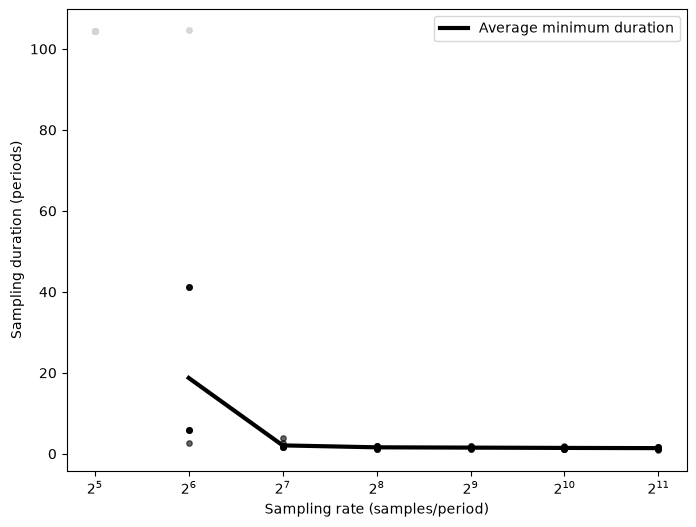

In [25]:
success = df[df["status"] == 1]
failure = df[df["status"] == 0]


boundary = (
    success
    .groupby("samples_per_period")["duration_periods"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8,6))

plt.scatter(
    failure["samples_per_period"],
    failure["duration_periods"],
    color="lightgray",
    s=15,
    alpha=0.6
)

plt.scatter(
    success["samples_per_period"],
    success["duration_periods"],
    color="black",
    s=15,
    alpha=0.6
)

plt.plot(
    boundary["samples_per_period"],
    boundary["duration_periods"],
    "k-",
    linewidth=3,
    label="Average minimum duration"
)

plt.xscale("log", base=2)

plt.xlabel("Sampling rate (samples/period)")
plt.ylabel("Sampling duration (periods)")

plt.legend()
plt.show()